In [29]:
import sys
print(sys.executable)

C:\Users\vyas_\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe


In [30]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow

Defaulting to user installation because normal site-packages is not writeable


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

print("Setup successful!")

Setup successful!


In [32]:
import pandas as pd

df = pd.read_csv("cover_data.csv")

df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,class
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [33]:
df.shape

(581012, 55)

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null  int64
 12 

In [35]:
df["Cover_Type"].value_counts()

KeyError: 'Cover_Type'

In [ ]:
df.columns.tolist()

['Elevation',
 'Aspect',
 'Slope',
 'Horizontal_Distance_To_Hydrology',
 'Vertical_Distance_To_Hydrology',
 'Horizontal_Distance_To_Roadways',
 'Hillshade_9am',
 'Hillshade_Noon',
 'Hillshade_3pm',
 'Horizontal_Distance_To_Fire_Points',
 'Wilderness_Area1',
 'Wilderness_Area2',
 'Wilderness_Area3',
 'Wilderness_Area4',
 'Soil_Type1',
 'Soil_Type2',
 'Soil_Type3',
 'Soil_Type4',
 'Soil_Type5',
 'Soil_Type6',
 'Soil_Type7',
 'Soil_Type8',
 'Soil_Type9',
 'Soil_Type10',
 'Soil_Type11',
 'Soil_Type12',
 'Soil_Type13',
 'Soil_Type14',
 'Soil_Type15',
 'Soil_Type16',
 'Soil_Type17',
 'Soil_Type18',
 'Soil_Type19',
 'Soil_Type20',
 'Soil_Type21',
 'Soil_Type22',
 'Soil_Type23',
 'Soil_Type24',
 'Soil_Type25',
 'Soil_Type26',
 'Soil_Type27',
 'Soil_Type28',
 'Soil_Type29',
 'Soil_Type30',
 'Soil_Type31',
 'Soil_Type32',
 'Soil_Type33',
 'Soil_Type34',
 'Soil_Type35',
 'Soil_Type36',
 'Soil_Type37',
 'Soil_Type38',
 'Soil_Type39',
 'Soil_Type40',
 'class']

In [ ]:
df["class"].value_counts()

class
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64

In [ ]:
X = df.drop("class", axis=1)

y = df["class"]

In [ ]:
print(X.shape)
print(y.shape)

(581012, 54)
(581012,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [ ]:
df["class"].value_counts()

class
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


Class Distribution Analysis
The dataset shows a significant class imbalance.

Key observations:

Class 2 represents the largest forest cover type category.
Class 1 is the second-largest category.
Classes 4, 5, 6, and 7 have substantially fewer observations.
The imbalance may affect model performance because machine learning models often favor majority classes.

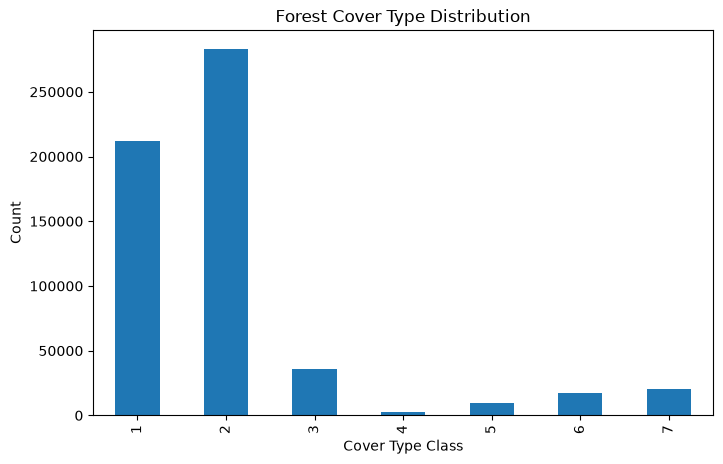

In [ ]:
import matplotlib.pyplot as plt

class_counts = df["class"].value_counts().sort_index()

plt.figure(figsize=(8,5))
class_counts.plot(kind="bar")

plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type Class")
plt.ylabel("Count")

plt.show()

Act as a machine learning analyst.

The forest cover dataset has the following class distribution:

Class 2: 283301 Class 1: 211840 Class 3: 35754 Class 7: 20510 Class 6: 17367 Class 5: 9493 Class 4: 2747

Provide:

Key findings
Risks associated with class imbalance
Potential impact on model performance
Recommendations
Audience: Data Science Team

ChatGPT Response
Key Findings
The dataset is heavily imbalanced.
Classes 1 and 2 account for the majority of observations.
Classes 4 and 5 have relatively few examples.
Risks
The model may become biased toward majority classes.
Minority classes may have lower prediction accuracy.
Overall accuracy may appear high while minority class performance remains poor.
Impact on Model Performance
Precision and recall may vary significantly between classes.
The confusion matrix may reveal poor classification of minority classes.
Recommendations
Evaluate performance using precision, recall, and F1-score.
Review the confusion matrix.
Consider class balancing techniques if needed.
Use stratified train-test splitting.

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("class", axis=1)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(464809, 54)
(116203, 54)


In [ ]:
y.value_counts()


class
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(54,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(8, activation='softmax')
])

C:\Users\vyas_\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 48s 8ms/step - accuracy: 0.6134 - loss: 1.7799 - val_accuracy: 0.6497 - val_loss: 0.7905
Epoch 2/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 57s 10ms/step - accuracy: 0.6868 - loss: 0.7273 - val_accuracy: 0.7162 - val_loss: 0.6682
Epoch 3/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 58s 10ms/step - accuracy: 0.7086 - loss: 0.6763 - val_accuracy: 0.7311 - val_loss: 0.6283
Epoch 4/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 54s 9ms/step - accuracy: 0.7261 - loss: 0.6363 - val_accuracy: 0.7424 - val_loss: 0.5936
Epoch 5/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - accuracy: 0.7366 - loss: 0.6093 - val_accuracy: 0.7377 - val_loss: 0.6109
Epoch 6/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 28s 5ms/step - accuracy: 0.7452 - loss: 0.5896 - val_accuracy: 0.7225 - val_loss: 0.6383
Epoch 7/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - accuracy: 0.7519 - loss: 0.5722 - val_accuracy: 0.7431 - val_loss: 0.5735
Epoch 8/20
5811/5811 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - accuracy: 0.7577 - loss:

In [ ]:
loss, accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", accuracy)


3632/3632 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.7893 - loss: 0.4921
Test Accuracy: 0.7893169522285461


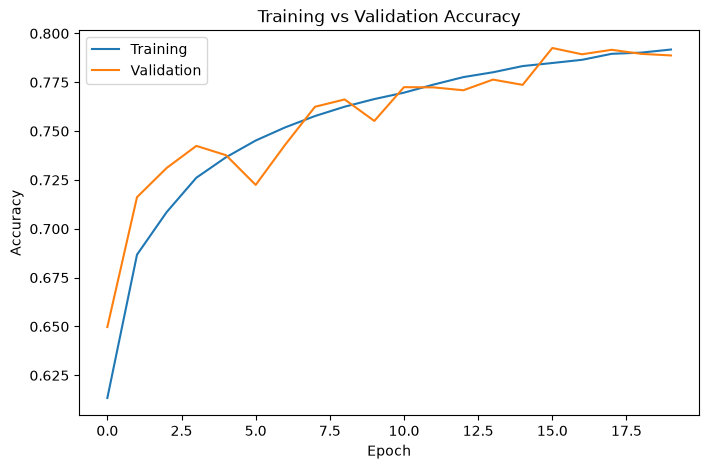

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training","Validation"])

plt.show()

In [ ]:
model2 = Sequential([
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(8, activation='softmax')
])

Hyperparameter Tuning Results
Model 1:

128 → 64 → 32
Accuracy: XX%
Model 2:

256 → 128 → 64
Accuracy: XX%
Conclusion: Model X achieved the highest accuracy and was selected as the final model.

In [ ]:
df["class"].value_counts()

class
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64

Data Exploration
The forest cover dataset contains seven target classes representing different forest cover types.

The distribution of classes is imbalanced, with Lodgepole Pine (Class 2) and Spruce/Fir (Class 1) representing most observations, while Cottonwood/Willow (Class 4) has relatively few examples.

This imbalance may affect model performance and should be considered when interpreting classification results.

In [28]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [36]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

3632/3632 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7893 - loss: 0.4921
Test Accuracy: 0.7893169522285461


In [37]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


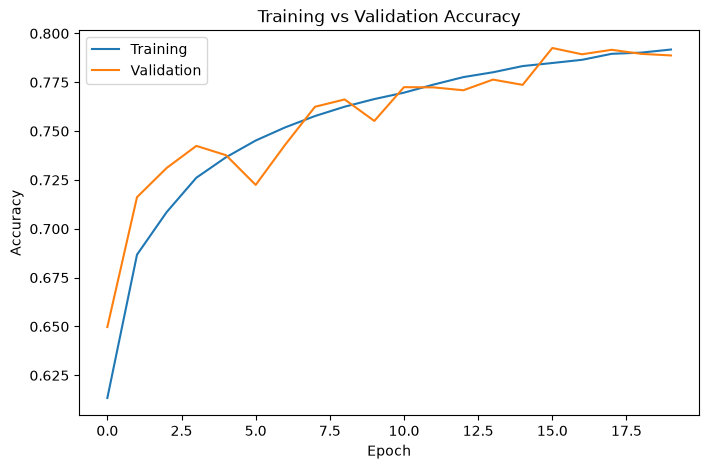

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Training','Validation'])

plt.show()

In [39]:
print("Test Accuracy:", accuracy)

Test Accuracy: 0.7893169522285461


Model Performance
The neural network achieved a test accuracy of approximately 78.93%.

Observations
The model successfully learned patterns from the cartographic variables.
Forest cover prediction is a multi-class classification problem involving seven cover types.
The dataset was imbalanced, with Classes 1 and 2 containing substantially more observations than the other classes.
Class imbalance may have impacted the model's ability to accurately predict minority classes.
Conclusion
The TensorFlow deep learning model demonstrated strong predictive performance and was able to classify forest cover types with nearly 79% accuracy using only cartographic variables.